In [14]:
import pandas as pd

URL = "https://raw.githubusercontent.com/BenniLan/poe-prices/main/ninja_snapshots.csv"
df = pd.read_csv(URL, parse_dates=["time"])

print(df.shape)
print(df["time"].min(), df["time"].max())
print(df["league"].unique())

(100, 7)
2026-10-29 15:41:44.639395+00:00 2026-10-29 15:41:44.639395+00:00
<StringArray>
['Allflame']
Length: 1, dtype: str


<Axes: title={'center': 'Divine Orb in Chaos'}, xlabel='time'>

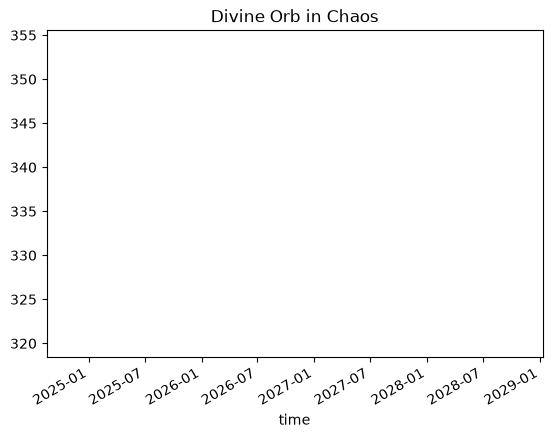

In [15]:
div = df[df["name"] == "Divine Orb"].set_index("time").sort_index()
div["primaryValue"].plot(title="Divine Orb in Chaos")

In [17]:
wide = df.pivot_table(index="time", columns="name", values="primaryValue")
print(wide[["Divine Orb"]].tail())

name                              Divine Orb
time                                        
2026-10-29 15:41:44.639395+00:00       337.0


In [19]:
import pandas as pd
d = pd.read_csv(r"C:\Users\benja\Desktop\Poe_Prize_Detector\Mirage.currency.csv", sep=None, engine="python")
print(d.shape); print(d.head()); print(d.columns.tolist())

(28837, 6)
   League        Date            Get        Pay    Value Confidence
0  Mirage  2026-03-06  Chromatic Orb  Chaos Orb  0.18167       High
1  Mirage  2026-03-07  Chromatic Orb  Chaos Orb  0.14286       High
2  Mirage  2026-03-08  Chromatic Orb  Chaos Orb  0.14858       High
3  Mirage  2026-03-09  Chromatic Orb  Chaos Orb  0.14286       High
4  Mirage  2026-03-10  Chromatic Orb  Chaos Orb  0.14184       High
['League', 'Date', 'Get', 'Pay', 'Value', 'Confidence']


2026-03-06 00:00:00 2026-07-20 00:00:00
Confidence
High      13010
Low       10412
Medium     5415
Name: count, dtype: int64
Pay
Chaos Orb             24267
Divine Orb              137
Hinekora's Lock         135
Mirror of Kalandra      135
Ancient Orb             131
Name: count, dtype: int64
            Value Confidence
Date                        
2026-03-06   36.3       High
2026-03-07   86.2       High
2026-03-08   97.9       High
2026-03-09  145.0       High
2026-03-10  169.1       High
2026-03-11  171.4       High
2026-03-12  175.0       High
2026-03-13  175.8       High
2026-03-14  180.0       High
2026-03-15  191.0       High
count    137.00000
mean     379.76910
std      141.04724
min       36.30000
25%      274.70000
50%      368.00000
75%      500.00000
max      612.00000
Name: Value, dtype: float64


<Axes: title={'center': 'Divine Orb in Chaos, Mirage'}, xlabel='Date'>

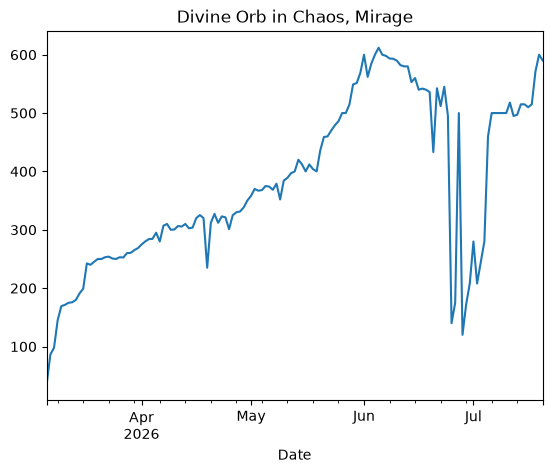

In [20]:
d["Date"] = pd.to_datetime(d["Date"])
print(d["Date"].min(), d["Date"].max())
print(d["Confidence"].value_counts())
print(d["Pay"].value_counts().head())

div = (d[(d["Get"] == "Divine Orb") & (d["Pay"] == "Chaos Orb")]
         .set_index("Date").sort_index())
print(div[["Value", "Confidence"]].head(10))
print(div["Value"].describe())
div["Value"].plot(title="Divine Orb in Chaos, Mirage")

In [21]:
import numpy as np

print(div["Confidence"].value_counts())            # is Divine mostly High?
print(div.index.to_series().diff().value_counts()) # confirm no gaps

lr = np.log(div["Value"]).diff().dropna()          # log change per day
day = (lr.index - div.index.min()).days
phase = pd.cut(day, [0, 7, 28, 1000], labels=["days 1-7", "days 8-28", "later"])

tmp = pd.DataFrame({"lr": lr.values, "abs": lr.abs().values, "phase": phase})
print(tmp.groupby("phase", observed=True)[["lr", "abs"]].agg(["mean", "std"]))

Confidence
High      129
Medium      8
Name: count, dtype: int64
Date
1 days    136
Name: count, dtype: int64
                 lr                 abs          
               mean       std      mean       std
phase                                            
days 1-7   0.225361  0.312840  0.225361  0.312840
days 8-28  0.022839  0.043326  0.025487  0.041746
later      0.006770  0.233171  0.087776  0.215959


In [22]:
c = d[d["Pay"] == "Chaos Orb"].copy()
c["Date"] = pd.to_datetime(c["Date"])
c["lv"] = np.log(c["Value"])

stats = c.groupby("Get").agg(
    days=("Date", "nunique"),
    high_share=("Confidence", lambda s: (s == "High").mean()),
    median_price=("Value", "median"),
    volatility=("lv", lambda s: s.diff().std()),
)
print(stats[(stats["days"] > 100) & (stats["high_share"] > 0.6)]
      .sort_values("volatility", ascending=False).head(25))

                                  days  high_share  median_price  volatility
Get                                                                         
Scroll of Wisdom                   137    0.620438      0.065000    1.076838
Timeless Vaal Splinter             136    0.764706      2.000000    0.801628
Noxious Catalyst                   136    0.661765      2.000000    0.781125
Voidborn Reliquary Key             137    1.000000     57.500000    0.748414
Timeless Eternal Empire Splinter   136    0.742647      2.850000    0.701392
Timeless Templar Splinter          136    0.691176      4.250000    0.673098
Timeless Karui Splinter            136    0.779412      2.600000    0.662766
Orb of Conflict                    136    0.720588    460.890000    0.656854
Timeless Maraketh Splinter         136    0.610294      5.000000    0.579241
Orb of Unmaking                    136    0.683824      0.477000    0.572579
Prismatic Catalyst                 136    0.639706      8.350000    0.565852

                          name  days  median_abs_move  p95_abs_move  \
0       Voidborn Reliquary Key   137            0.248         2.110   
1            Volatile Vaal Orb   136            0.055         1.239   
2              Orb of Conflict   136            0.041         0.457   
3    An Audience With The King   136            0.131         1.087   
4  Wild Crystallised Lifeforce   136            0.033         0.352   
5              The Black Barya   136            0.182         1.304   
6                   Simulacrum   136            0.131         0.762   
7          Simulacrum Splinter   137            0.000         0.759   

   zero_change_share  unique_prices  
0              0.044            112  
1              0.089            120  
2              0.022            128  
3              0.156             78  
4              0.089            116  
5              0.178             92  
6              0.341             69  
7              0.610             28  


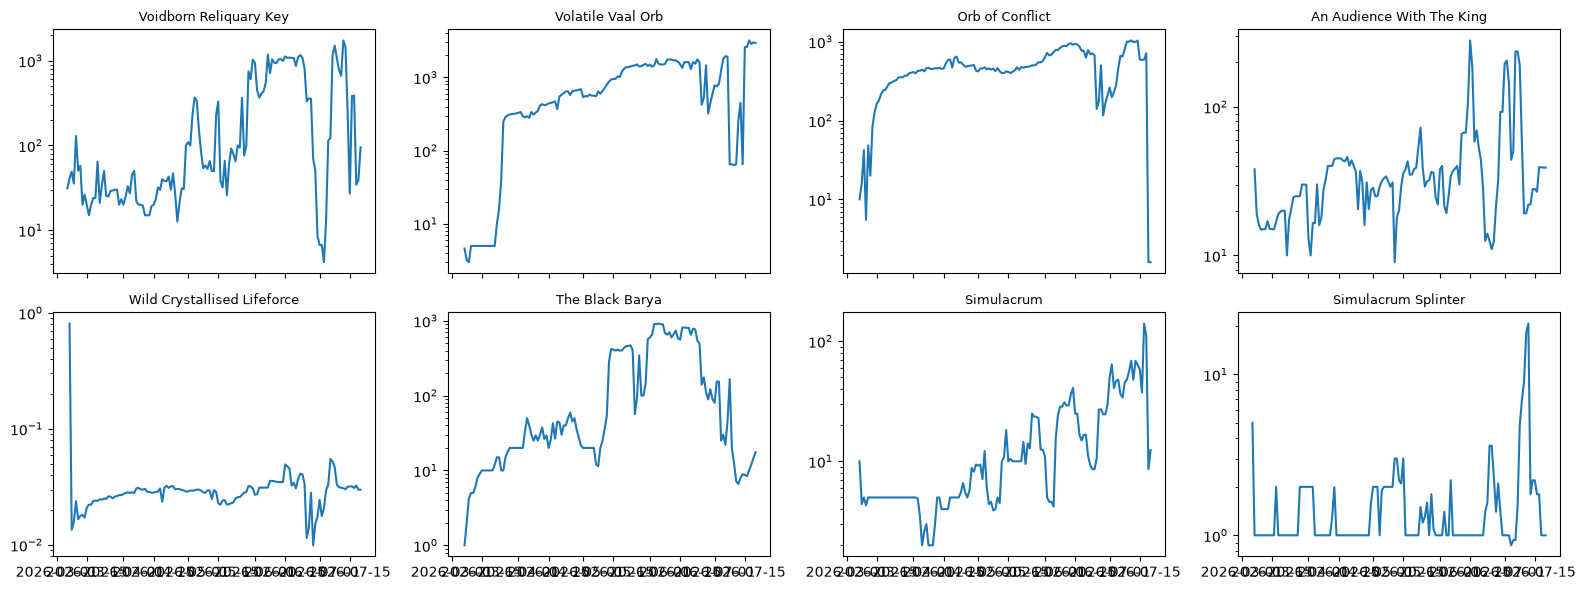

In [23]:
picks = ["Voidborn Reliquary Key", "Volatile Vaal Orb", "Orb of Conflict",
         "An Audience With The King", "Wild Crystallised Lifeforce",
         "The Black Barya", "Simulacrum", "Simulacrum Splinter"]

rows = []
for name in picks:
    s = (c[c["Get"] == name].set_index("Date")["Value"].sort_index())
    lr = np.log(s).diff().dropna()
    late = lr[(lr.index - s.index.min()).days > 28]         # skip league start
    rows.append({"name": name, "days": len(s),
                 "median_abs_move": late.abs().median(),     # robust volatility
                 "p95_abs_move": late.abs().quantile(0.95),
                 "zero_change_share": (lr == 0).mean(),      # quantization check
                 "unique_prices": s.nunique()})
print(pd.DataFrame(rows).round(3))

import matplotlib.pyplot as plt
fig, ax = plt.subplots(2, 4, figsize=(16, 6), sharex=True)
for a, name in zip(ax.ravel(), picks):
    s = c[c["Get"] == name].set_index("Date")["Value"].sort_index()
    a.plot(s); a.set_title(name, fontsize=9); a.set_yscale("log")
plt.tight_layout(); plt.show()

-0.06528293553369517
-0.03799031744642338
Date
0    65.750
1    50.000
2    50.000
3    92.000
4    71.750
5    39.375
6    51.000
Name: Value, dtype: float64


C:\Users\benja\AppData\Local\Temp\ipykernel_11680\853805130.py:9: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  print(s.groupby(s.index.dayofweek).median())    # weekday pattern?


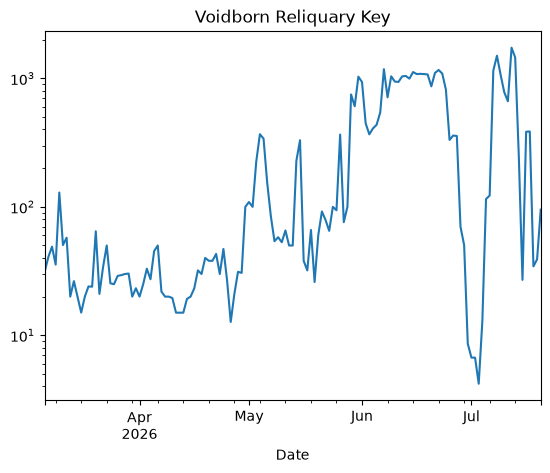

In [24]:
s = c[c["Get"] == "Voidborn Reliquary Key"].set_index("Date")["Value"].sort_index()
lr = np.log(s).diff().dropna()

print(lr.autocorr(lag=1))                       # negative = spikes tend to reverse
dev = np.log(s) - np.log(s).rolling(7).median() # distance from the recent normal
print(dev.shift(1).corr(lr))                    # negative = high price today -> fall tomorrow

s.plot(logy=True, title="Voidborn Reliquary Key")
print(s.groupby(s.index.dayofweek).median())    # weekday pattern?

In [26]:
from scipy import stats
groups = [lr[lr.index.dayofweek == k].values for k in range(7)]
print(stats.kruskal(*groups))

C:\Users\benja\AppData\Local\Temp\ipykernel_11680\2245799392.py:2: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  groups = [lr[lr.index.dayofweek == k].values for k in range(7)]
C:\Users\benja\AppData\Local\Temp\ipykernel_11680\2245799392.py:2: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  groups = [lr[lr.index.dayofweek == k].values for k in range(7)]
C:\Users\benja\AppData\Local\Temp\ipykernel_11680\2245799392.py:2: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  groups = [lr[lr.index.dayofweek == k].values for k in range(7)]


KruskalResult(statistic=np.float64(10.715048353342139), pvalue=np.float64(0.09759265503914963))


C:\Users\benja\AppData\Local\Temp\ipykernel_11680\2245799392.py:2: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  groups = [lr[lr.index.dayofweek == k].values for k in range(7)]
C:\Users\benja\AppData\Local\Temp\ipykernel_11680\2245799392.py:2: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  groups = [lr[lr.index.dayofweek == k].values for k in range(7)]
C:\Users\benja\AppData\Local\Temp\ipykernel_11680\2245799392.py:2: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  groups = [lr[lr.index.dayofweek == k].values for k in range(7)]
C:\Users\benja\AppData\Local\Temp\ipykernel_11680\2245799392.py:2: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead

In [27]:
print([round(lr.autocorr(k), 3) for k in range(1, 8)])

[np.float64(-0.065), np.float64(-0.189), np.float64(0.189), np.float64(0.018), np.float64(-0.062), np.float64(-0.077), np.float64(-0.281)]


In [28]:
p = np.log(s)
naive = (p.shift(-1) - p).abs()                      # error of "tomorrow = today"
med7  = (p.shift(-1) - p.rolling(7).median()).abs()  # predict the 7-day median
cmp = pd.DataFrame({"naive": naive, "median7": med7}).dropna()
print(cmp.median(), cmp.mean())

naive      0.256009
median7    0.418022
dtype: float64 naive      0.466371
median7    0.804176
dtype: float64


In [29]:
def check(name, df=c):
    s = df[df["Get"] == name].set_index("Date")["Value"].sort_index()
    p = np.log(s)
    lr = p.diff().dropna()
    late = (p.index - p.index.min()).days > 28            # skip league start
    out = pd.DataFrame({
        "naive":   (p.shift(-1) - p).abs(),
        "median7": (p.shift(-1) - p.rolling(7).median()).abs(),
        "mean3":   (p.shift(-1) - p.rolling(3).mean()).abs(),
    })[late].dropna()
    print(name)
    print("  autocorr lags 1-5:", [round(lr.autocorr(k), 3) for k in range(1, 6)])
    print("  median error:", out.median().round(3).to_dict())

for n in ["Orb of Conflict", "Wild Crystallised Lifeforce", "Volatile Vaal Orb"]:
    check(n)

Orb of Conflict
  autocorr lags 1-5: [np.float64(-0.197), np.float64(0.133), np.float64(0.02), np.float64(0.151), np.float64(0.012)]
  median error: {'naive': 0.043, 'median7': 0.118, 'mean3': 0.062}
Wild Crystallised Lifeforce
  autocorr lags 1-5: [np.float64(-0.172), np.float64(-0.238), np.float64(0.194), np.float64(-0.027), np.float64(-0.023)]
  median error: {'naive': 0.033, 'median7': 0.062, 'mean3': 0.051}
Volatile Vaal Orb
  autocorr lags 1-5: [np.float64(-0.16), np.float64(-0.015), np.float64(0.142), np.float64(-0.124), np.float64(-0.062)]
  median error: {'naive': 0.056, 'median7': 0.15, 'mean3': 0.074}


In [30]:
def ar_test(name, df=c, min_train=30):
    s = df[df["Get"] == name].set_index("Date")["Value"].sort_index()
    p = np.log(s); lr = p.diff()
    naive_err, ar_err = [], []
    for t in range(min_train, len(p) - 1):
        hist = lr.iloc[1:t + 1]                     # changes known up to day t
        x = hist.shift(1).dropna(); y = hist.loc[x.index]
        phi = (x * y).sum() / (x * x).sum()         # fitted on the past only
        actual = lr.iloc[t + 1]
        naive_err.append(abs(actual))
        ar_err.append(abs(actual - phi * lr.iloc[t]))
    print(name, "naive:", round(np.median(naive_err), 4),
          "AR:", round(np.median(ar_err), 4),
          "mean naive:", round(np.mean(naive_err), 4),
          "mean AR:", round(np.mean(ar_err), 4))

for n in ["Orb of Conflict", "Wild Crystallised Lifeforce", "Volatile Vaal Orb"]:
    ar_test(n)

Orb of Conflict naive: 0.041 AR: 0.0563 mean naive: 0.1753 mean AR: 0.2239
Wild Crystallised Lifeforce naive: 0.034 AR: 0.0285 mean naive: 0.1002 mean AR: 0.0994
Volatile Vaal Orb naive: 0.0574 AR: 0.0616 mean naive: 0.2173 mean AR: 0.2443


In [31]:
def val(name):
    return c[c["Get"] == name].set_index("Date")["Value"].sort_index()

div_v = val("Divine Orb")
d0 = div_v.index.min()
t_a, t_b = d0 + pd.Timedelta(days=3), d0 + pd.Timedelta(days=14)

rows = []
for name in c["Get"].unique():
    s = val(name)
    if t_a in s.index and t_b in s.index:
        chg = np.log(s[t_b] / s[t_a])
        rel = chg - np.log(div_v[t_b] / div_v[t_a])      # relative to Divine
        rows.append((name, chg, rel))
r = pd.DataFrame(rows, columns=["name", "chaos_change", "vs_divine"]).sort_values("vs_divine")
print(r.describe().round(2))
print(r.head(8)); print(r.tail(8))

       chaos_change  vs_divine
count        179.00     179.00
mean           0.42      -0.13
std            0.96       0.96
min           -2.97      -3.52
25%           -0.02      -0.57
50%            0.43      -0.12
75%            1.02       0.47
max            3.27       2.73
                                    name  chaos_change  vs_divine
144    Unrelenting Timeless Karui Emblem     -2.974219  -3.518946
121  Unrelenting Timeless Eternal Emblem     -2.458002  -3.002729
148                Tainted Orb of Fusing     -2.000304  -2.545031
83                    Devouring Fragment     -1.649068  -2.193795
174                   Tainted Mythic Orb     -1.435185  -1.979912
80                  Hunter's Exalted Orb     -1.412390  -1.957118
98          Foulborn Orb of Augmentation     -1.386294  -1.931022
171                   Orb of Unravelling     -1.287494  -1.832221
                                    name  chaos_change  vs_divine
138                  Syndicate Medallion      1.961552   1.41

In [32]:
def logv(name, day):
    s = val(name)
    t = d0 + pd.Timedelta(days=day)
    # average a 3-day window to reduce one-day noise
    w = s[(s.index >= t - pd.Timedelta(days=1)) & (s.index <= t + pd.Timedelta(days=1))]
    return np.log(w).mean() if len(w) >= 2 else np.nan

dv = lambda day: np.log(div_v[d0 + pd.Timedelta(days=day)])
rows = []
for name in c["Get"].unique():
    a, b, e = logv(name, 3), logv(name, 8), logv(name, 14)
    if np.isnan([a, b, e]).any(): continue
    rows.append((name,
                 (b - a) - (dv(8) - dv(3)),     # early relative move
                 (e - b) - (dv(14) - dv(8))))   # later relative move
t = pd.DataFrame(rows, columns=["name", "early", "later"])
print(len(t))
print(stats.spearmanr(t["early"], t["later"]))

179
SignificanceResult(statistic=np.float64(0.16930531800987436), pvalue=np.float64(0.023472020464853964))


In [33]:
import glob, os
import pandas as pd

folder = r"C:\Users\benja\Desktop\Poe_Prize_Detector"

frames = []
for f in glob.glob(os.path.join(folder, "**", "*.currency.csv"), recursive=True):
    x = pd.read_csv(f, sep=None, engine="python", parse_dates=["Date"])
    x = x[x["Pay"] == "Chaos Orb"]
    frames.append(x)
    print(os.path.basename(f), len(x))      # shows which files were picked up

allc = pd.concat(frames, ignore_index=True)
allc["day"] = (allc["Date"] - allc.groupby("League")["Date"].transform("min")).dt.days
print(allc.groupby("League").agg(start=("Date", "min"), end=("Date", "max"),
                                 currencies=("Get", "nunique")))

Keepers.currency.csv 23575
Mercenaries.currency.csv 26906
Mirage.currency.csv 24267
Phrecia.currency.csv 11860
Settlers.currency.csv 60802
                 start        end  currencies
League                                       
Keepers     2025-10-31 2026-03-02         200
Mercenaries 2025-06-13 2025-10-27         198
Mirage      2026-03-06 2026-07-20         183
Phrecia     2025-02-20 2025-04-23         192
Settlers    2024-07-26 2025-06-09         192


In [35]:
def persistence(league, a=3, b=7, c0=10, e=14, w=1, drop_low=True):
    L = allc[allc["League"] == league]
    if drop_low:
        L = L[L["Confidence"] != "Low"]
    lp = np.log(L.pivot_table(index="day", columns="Get", values="Value"))
    lvl = lambda d: lp.loc[d - w: d + w].mean()          # 3-day average to cut noise
    DIV = "Divine Orb"
    early = (lvl(b) - lvl(a)) - (lvl(b)[DIV] - lvl(a)[DIV])   # move vs Divine, days 3-7
    later = (lvl(e) - lvl(c0)) - (lvl(e)[DIV] - lvl(c0)[DIV]) # move vs Divine, days 10-14
    t = pd.DataFrame({"early": early, "later": later}).dropna().drop(DIV, errors="ignore")
    rho, p = stats.spearmanr(t["early"], t["later"])
    return len(t), round(rho, 3), round(p, 3)

for lg in allc["League"].unique():
    print(lg, persistence(lg))

Keepers (185, np.float64(0.194), np.float64(0.008))
Mercenaries (191, np.float64(0.47), np.float64(0.0))
Mirage (156, np.float64(0.194), np.float64(0.015))
Settlers (183, np.float64(0.547), np.float64(0.0))


In [36]:
allc = allc[allc["League"] != "Phrecia"]
allc = allc[allc["day"] <= 60]          # only the early part matters

# duplicates check (should be all zeros) and Divine's first two weeks per league
print(allc.duplicated(["League", "Date", "Get"]).groupby(allc["League"]).sum())
D = allc[allc["Get"] == "Divine Orb"].pivot_table(index="day", columns="League", values="Value")
print(D.loc[0:14].round(0))

for lg in allc["League"].unique():
    print(lg, persistence(lg))

League
Keepers        0
Mercenaries    0
Mirage         0
Settlers       0
dtype: int64
League  Keepers  Mercenaries  Mirage  Settlers
day                                           
0          45.0         55.0    36.0      58.0
1          88.0         95.0    86.0      71.0
2          96.0        130.0    98.0      93.0
3         102.0        158.0   145.0     115.0
4          98.0        155.0   169.0     124.0
5         100.0        151.0   171.0     140.0
6         112.0        151.0   175.0     150.0
7         139.0        152.0   176.0     151.0
8         134.0        153.0   180.0     148.0
9         130.0        155.0   191.0     148.0
10        129.0        157.0   199.0     150.0
11        128.0        157.0   242.0     150.0
12        124.0        157.0   240.0     150.0
13        119.0        159.0   245.0     152.0
14        116.0        164.0   250.0     155.0
Keepers (185, np.float64(0.194), np.float64(0.008))
Mercenaries (191, np.float64(0.47), np.float64(0.0))
Mirage (

In [37]:
def pairs(league, drop_low=True, min_price=2):
    L = allc[allc["League"] == league]
    if drop_low:
        L = L[L["Confidence"] != "Low"]
    lp = np.log(L.pivot_table(index="day", columns="Get", values="Value"))
    keep = L.groupby("Get")["Value"].median()
    lp = lp[keep[keep > min_price].index.intersection(lp.columns)]   # drop cheap, quantized ones
    lvl = lambda d: lp.loc[d-1:d+1].mean()
    DIV = "Divine Orb"
    early = (lvl(7) - lvl(3)) - (lvl(7)[DIV] - lvl(3)[DIV])
    later = (lvl(14) - lvl(10)) - (lvl(14)[DIV] - lvl(10)[DIV])
    return pd.DataFrame({"early": early, "later": later}).dropna().drop(DIV, errors="ignore")

P = {lg: pairs(lg) for lg in allc["League"].unique()}
for test in P:
    train = pd.concat([P[k] for k in P if k != test])
    beta = (train["early"] * train["later"]).sum() / (train["early"] ** 2).sum()
    te = P[test]
    base = te["later"].abs().median()
    model = (te["later"] - beta * te["early"]).abs().median()
    print(f"{test:12s} beta={beta:.2f}  baseline MAE={base:.3f}  model MAE={model:.3f}")

Keepers      beta=0.15  baseline MAE=0.166  model MAE=0.170
Mercenaries  beta=0.06  baseline MAE=0.139  model MAE=0.129
Mirage       beta=0.11  baseline MAE=0.189  model MAE=0.200
Settlers     beta=0.05  baseline MAE=0.120  model MAE=0.097


In [39]:
order = allc.groupby("League")["Date"].min().sort_values().index.tolist()
for lg in order:
    t = P[lg]
    print(f"{lg:12s} n={len(t):3d}  spearman={stats.spearmanr(t['early'], t['later'])[0]:.3f}")

Settlers     n=109  spearman=0.524
Mercenaries  n=131  spearman=0.345
Keepers      n=115  spearman=0.112
Mirage       n=111  spearman=0.120


In [40]:
for i in range(1, len(order)):
    train = pd.concat([P[k] for k in order[:i]])
    beta = (train["early"] * train["later"]).sum() / (train["early"] ** 2).sum()
    te = P[order[i]]
    print(f"{order[i]:12s} (trained on {i} older)  beta={beta:.2f}  "
          f"baseline={te['later'].abs().median():.3f}  "
          f"model={(te['later'] - beta * te['early']).abs().median():.3f}")

Mercenaries  (trained on 1 older)  beta=0.27  baseline=0.139  model=0.173
Keepers      (trained on 2 older)  beta=0.22  baseline=0.166  model=0.177
Mirage       (trained on 3 older)  beta=0.11  baseline=0.189  model=0.200


In [41]:
order = allc.groupby("League")["Date"].min().sort_values().index.tolist()   # oldest to newest

for lg in order:
    t = P[lg]
    q = pd.qcut(t["early"], 5, labels=False)
    top = t.loc[q == 4, "later"].median()
    bot = t.loc[q == 0, "later"].median()
    print(f"{lg:12s} top fifth: {top:+.3f}  bottom fifth: {bot:+.3f}  gap: {top-bot:+.3f}  (n={int((q==4).sum())} each)")

Settlers     top fifth: +0.252  bottom fifth: -0.046  gap: +0.298  (n=22 each)
Mercenaries  top fifth: +0.185  bottom fifth: -0.107  gap: +0.292  (n=22 each)
Keepers      top fifth: +0.151  bottom fifth: +0.123  gap: +0.028  (n=23 each)
Mirage       top fifth: -0.013  bottom fifth: -0.170  gap: +0.156  (n=22 each)


In [42]:
rng = np.random.default_rng(0)
for lg in order:
    t = P[lg]
    q = pd.qcut(t["early"], 5, labels=False)
    top = t.loc[q == 4, "later"].values
    bot = t.loc[q == 0, "later"].values
    gaps = [np.median(rng.choice(top, len(top))) - np.median(rng.choice(bot, len(bot)))
            for _ in range(5000)]
    lo, hi = np.percentile(gaps, [5, 95])
    print(f"{lg:12s} gap {np.median(top)-np.median(bot):+.3f}   90% interval [{lo:+.3f}, {hi:+.3f}]")

Settlers     gap +0.298   90% interval [+0.195, +0.374]
Mercenaries  gap +0.292   90% interval [+0.130, +0.521]
Keepers      gap +0.028   90% interval [-0.128, +0.167]
Mirage       gap +0.156   90% interval [-0.108, +0.321]


In [43]:
def gap_w(league, a, b, c0, e, min_price=2):
    L = allc[(allc["League"] == league) & (allc["Confidence"] != "Low")]
    lp = np.log(L.pivot_table(index="day", columns="Get", values="Value"))
    med = L.groupby("Get")["Value"].median()
    lp = lp[med[med > min_price].index.intersection(lp.columns)]
    lvl = lambda d: lp.loc[d-1:d+1].mean()
    DIV = "Divine Orb"
    early = (lvl(b) - lvl(a)) - (lvl(b)[DIV] - lvl(a)[DIV])
    later = (lvl(e) - lvl(c0)) - (lvl(e)[DIV] - lvl(c0)[DIV])
    t = pd.DataFrame({"early": early, "later": later}).dropna().drop(DIV, errors="ignore")
    q = pd.qcut(t["early"], 5, labels=False)
    return round(t.loc[q == 4, "later"].median() - t.loc[q == 0, "later"].median(), 3)

for w in [(3, 7, 10, 14), (2, 6, 9, 13), (4, 8, 11, 15), (3, 6, 9, 12)]:
    print(w, {lg: gap_w(lg, *w) for lg in order})

(3, 7, 10, 14) {'Settlers': np.float64(0.298), 'Mercenaries': np.float64(0.292), 'Keepers': np.float64(0.028), 'Mirage': np.float64(0.156)}
(2, 6, 9, 13) {'Settlers': np.float64(0.191), 'Mercenaries': np.float64(0.159), 'Keepers': np.float64(0.179), 'Mirage': np.float64(0.063)}
(4, 8, 11, 15) {'Settlers': np.float64(0.247), 'Mercenaries': np.float64(0.39), 'Keepers': np.float64(0.0), 'Mirage': np.float64(-0.007)}
(3, 6, 9, 12) {'Settlers': np.float64(0.181), 'Mercenaries': np.float64(0.203), 'Keepers': np.float64(0.184), 'Mirage': np.float64(0.163)}
